In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler

In [15]:
employee_df = pd.read_csv("employee_dataset_realistic.csv")
team_df = pd.read_csv("team_dataset_realistic.csv")

In [16]:
employee_df.head()

,team_id,employee_id,Name,Sum of Training Hours,Sum of Work Hours Logged,Sum of Peer Rating,Sum of KPI Score,Sum of Attendance (%),Sum of Manager Feedback,Sum of Performance Score,job_role,Promotion Eligibility,Sum of Task Completion (%),skills,domain,project_size
0,TEAM_001,202996,Zoya Wadhwa,9,43,4.3,82.90,79.83,5.0,100,Program Manager,Yes,71.51,Data Visualization;Portfolio Management;Strate...,Data Science,Large
1,TEAM_001,302189,Anahi Kari,16,49,4.9,76.14,79.21,3.2,59,Project Manager,No,93.45,Feature Engineering;Risk Management;Sprint Pla...,Data Science,Large
2,TEAM_001,376063,Manikya Badami,18,42,4.5,91.03,94.40,3.7,61,Tech Lead,No,78.19,System Architecture;Performance Optimization;S...,Data Science,Large
3,TEAM_001,383410,Baiju Doctor,29,51,3.7,90.90,89.92,3.1,80,Business Analyst,No,78.03,Documentation;Stakeholder Communication;Busine...,Data Science,Large
4,TEAM_001,520956,Sana Gera,7,51,4.4,65.39,99.50,3.5,100,UI/UX Designer,No,80.20,Statistics;Data Visualization;Model Evaluation...,Data Science,Large


In [17]:
team_df.shape

(782, 5)

In [18]:
employee_df.shape

(782, 16)

In [19]:
def clean_column_names(df):
    df.columns = (
        df.columns
        .str.strip()
        .str.lower()
        .str.replace(" ", "_")
        .str.replace("%", "percent")
    )
    return df

employee_df = clean_column_names(employee_df)
team_df = clean_column_names(team_df)

In [20]:
employee_df.shape

(782, 16)

In [21]:
employee_df.head()

,team_id,employee_id,name,sum_of_training_hours,sum_of_work_hours_logged,sum_of_peer_rating,sum_of_kpi_score,sum_of_attendance_(percent),sum_of_manager_feedback,sum_of_performance_score,job_role,promotion_eligibility,sum_of_task_completion_(percent),skills,domain,project_size
0,TEAM_001,202996,Zoya Wadhwa,9,43,4.3,82.90,79.83,5.0,100,Program Manager,Yes,71.51,Data Visualization;Portfolio Management;Strate...,Data Science,Large
1,TEAM_001,302189,Anahi Kari,16,49,4.9,76.14,79.21,3.2,59,Project Manager,No,93.45,Feature Engineering;Risk Management;Sprint Pla...,Data Science,Large
2,TEAM_001,376063,Manikya Badami,18,42,4.5,91.03,94.40,3.7,61,Tech Lead,No,78.19,System Architecture;Performance Optimization;S...,Data Science,Large
3,TEAM_001,383410,Baiju Doctor,29,51,3.7,90.90,89.92,3.1,80,Business Analyst,No,78.03,Documentation;Stakeholder Communication;Busine...,Data Science,Large
4,TEAM_001,520956,Sana Gera,7,51,4.4,65.39,99.50,3.5,100,UI/UX Designer,No,80.20,Statistics;Data Visualization;Model Evaluation...,Data Science,Large


In [22]:
feature_map = {
    "sum_of_task_completion_(%)": "task_completion_percentage",
    "sum_of_kpi_score": "kpi_score",
    "sum_of_attendance_(%)": "attendance_percentage",
    "sum_of_peer_rating": "peer_rating",
    "sum_of_training_hours": "training_hours"
}

# Rename if present
employee_df = employee_df.rename(columns=feature_map)

In [24]:
employee_df.head()

,team_id,employee_id,name,training_hours,sum_of_work_hours_logged,peer_rating,kpi_score,sum_of_attendance_(percent),sum_of_manager_feedback,sum_of_performance_score,job_role,promotion_eligibility,sum_of_task_completion_(percent),skills,domain,project_size
0,TEAM_001,202996,Zoya Wadhwa,9,43,4.3,82.90,79.83,5.0,100,Program Manager,Yes,71.51,Data Visualization;Portfolio Management;Strate...,Data Science,Large
1,TEAM_001,302189,Anahi Kari,16,49,4.9,76.14,79.21,3.2,59,Project Manager,No,93.45,Feature Engineering;Risk Management;Sprint Pla...,Data Science,Large
2,TEAM_001,376063,Manikya Badami,18,42,4.5,91.03,94.40,3.7,61,Tech Lead,No,78.19,System Architecture;Performance Optimization;S...,Data Science,Large
3,TEAM_001,383410,Baiju Doctor,29,51,3.7,90.90,89.92,3.1,80,Business Analyst,No,78.03,Documentation;Stakeholder Communication;Busine...,Data Science,Large
4,TEAM_001,520956,Sana Gera,7,51,4.4,65.39,99.50,3.5,100,UI/UX Designer,No,80.20,Statistics;Data Visualization;Model Evaluation...,Data Science,Large


In [25]:
feature_map = {
    "sum_of_task_completion_(percent)": "task_completion_percentage",
    "sum_of_attendance_(percent)": "attendance_percentage",
    "kpi_score": "kpi_score",
    "peer_rating": "peer_rating",
    "training_hours": "training_hours"
}

employee_df = employee_df.rename(columns=feature_map)

In [26]:
print(employee_df.columns)

Index(['team_id', 'employee_id', 'name', 'training_hours',
       'sum_of_work_hours_logged', 'peer_rating', 'kpi_score',
       'attendance_percentage', 'sum_of_manager_feedback',
       'sum_of_performance_score', 'job_role', 'promotion_eligibility',
       'task_completion_percentage', 'skills', 'domain', 'project_size'],
      dtype='object')


In [27]:
performance_features = [
    "task_completion_percentage",
    "kpi_score",
    "attendance_percentage",
    "peer_rating",
    "training_hours"
]

employee_perf_df = employee_df[
    ["employee_id", "team_id"] + performance_features
].copy()

In [28]:
print(employee_perf_df.head())

   employee_id   team_id  task_completion_percentage  kpi_score  \
0       202996  TEAM_001                       71.51      82.90   
1       302189  TEAM_001                       93.45      76.14   
2       376063  TEAM_001                       78.19      91.03   
3       383410  TEAM_001                       78.03      90.90   
4       520956  TEAM_001                       80.20      65.39   

   attendance_percentage  peer_rating  training_hours  
0                  79.83          4.3               9  
1                  79.21          4.9              16  
2                  94.40          4.5              18  
3                  89.92          3.7              29  
4                  99.50          4.4               7  


In [29]:
for col in performance_features:
    employee_perf_df[col] = employee_perf_df[col].fillna(
        employee_perf_df[col].median()
    )

In [30]:
print(employee_perf_df.head())

   employee_id   team_id  task_completion_percentage  kpi_score  \
0       202996  TEAM_001                       71.51      82.90   
1       302189  TEAM_001                       93.45      76.14   
2       376063  TEAM_001                       78.19      91.03   
3       383410  TEAM_001                       78.03      90.90   
4       520956  TEAM_001                       80.20      65.39   

   attendance_percentage  peer_rating  training_hours  
0                  79.83          4.3               9  
1                  79.21          4.9              16  
2                  94.40          4.5              18  
3                  89.92          3.7              29  
4                  99.50          4.4               7  


In [31]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

employee_perf_df[performance_features] = scaler.fit_transform(
    employee_perf_df[performance_features]
)

In [32]:
print(employee_perf_df[performance_features].describe())

       task_completion_percentage   kpi_score  attendance_percentage  \
count                  782.000000  782.000000             782.000000   
mean                     0.552158    0.483733               0.491948   
std                      0.296526    0.302397               0.305732   
min                      0.000000    0.000000               0.000000   
25%                      0.329252    0.233547               0.197641   
50%                      0.554252    0.447292               0.511387   
75%                      0.813946    0.758299               0.755185   
max                      1.000000    1.000000               1.000000   

       peer_rating  training_hours  
count   782.000000      782.000000  
mean      0.528964        0.508568  
std       0.292865        0.304884  
min       0.000000        0.000000  
25%       0.300000        0.266667  
50%       0.550000        0.500000  
75%       0.800000        0.766667  
max       1.000000        1.000000  


In [33]:
# Compute correlation matrix
corr_matrix = employee_perf_df[performance_features].corr()

print(corr_matrix)

                            task_completion_percentage  kpi_score  \
task_completion_percentage                    1.000000   0.078343   
kpi_score                                     0.078343   1.000000   
attendance_percentage                         0.070763   0.009070   
peer_rating                                   0.023569   0.072279   
training_hours                                0.097498   0.036939   

                            attendance_percentage  peer_rating  training_hours  
task_completion_percentage               0.070763     0.023569        0.097498  
kpi_score                                0.009070     0.072279        0.036939  
attendance_percentage                    1.000000     0.002806        0.170835  
peer_rating                              0.002806     1.000000       -0.027782  
training_hours                           0.170835    -0.027782        1.000000  


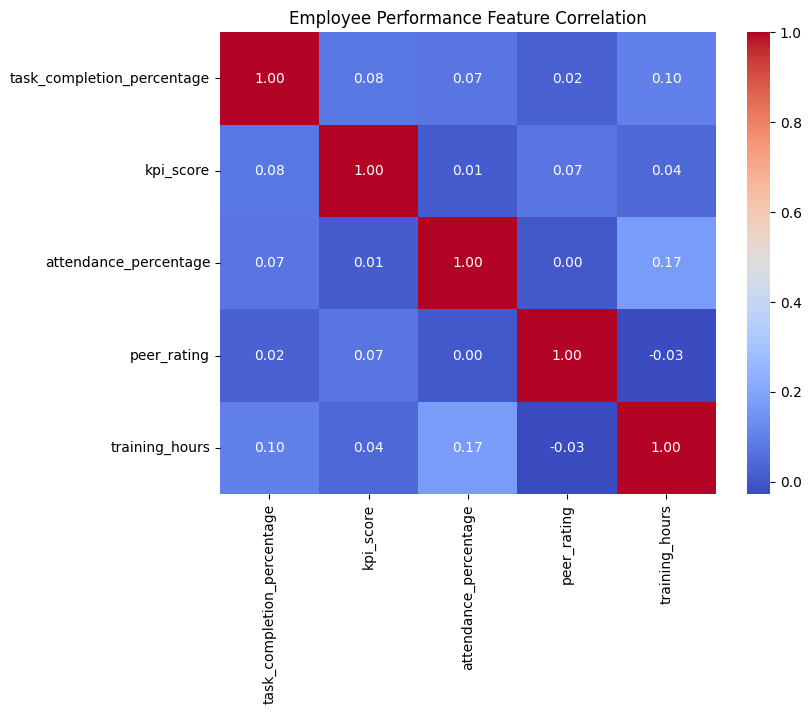

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Employee Performance Feature Correlation")
plt.show()

In [35]:
X = employee_perf_df[performance_features].values

# probability matrix
P = X / X.sum(axis=0)

n = X.shape[0]
epsilon = 1e-12

entropy = -np.sum(P * np.log(P + epsilon), axis=0) / np.log(n)

divergence = 1 - entropy

weights = divergence / divergence.sum()

weight_df = pd.DataFrame({
    "feature": performance_features,
    "entropy_weight": weights
})

print(weight_df)

                      feature  entropy_weight
0  task_completion_percentage        0.173852
1                   kpi_score        0.220144
2       attendance_percentage        0.223655
3                 peer_rating        0.173202
4              training_hours        0.209147


In [36]:
# compute employee performance score
employee_perf_df["employee_performance"] = np.dot(
    employee_perf_df[performance_features],
    weights
)

# preview
employee_perf_df[["employee_id","team_id","employee_performance"]].head()

,employee_id,team_id,employee_performance
0,202996,TEAM_001,0.369937
1,302189,TEAM_001,0.551462
2,376063,TEAM_001,0.674142
3,383410,TEAM_001,0.639021
4,520956,TEAM_001,0.482696


In [37]:
employee_perf_df["employee_performance"].describe()

,employee_performance
count,782.000000
mean,0.510494
std,0.149728
min,0.188989
25%,0.407596
50%,0.521184
75%,0.594781
max,0.873816


In [38]:
employee_perf_df.shape

(782, 8)

In [39]:
employee_perf_df.head()

,employee_id,team_id,task_completion_percentage,kpi_score,attendance_percentage,peer_rating,training_hours,employee_performance
0,202996,TEAM_001,0.047619,0.648515,0.194795,0.65,0.300000,0.369937
1,302189,TEAM_001,0.793878,0.451660,0.169581,0.95,0.533333,0.551462
2,376063,TEAM_001,0.274830,0.885265,0.787312,0.75,0.600000,0.674142
3,383410,TEAM_001,0.269388,0.881479,0.605124,0.35,0.966667,0.639021
4,520956,TEAM_001,0.343197,0.138614,0.994713,0.70,0.233333,0.482696


In [40]:
employee_performance_df = employee_perf_df[
    ["employee_id","team_id","employee_performance"]
].copy()

employee_performance_df.head()

,employee_id,team_id,employee_performance
0,202996,TEAM_001,0.369937
1,302189,TEAM_001,0.551462
2,376063,TEAM_001,0.674142
3,383410,TEAM_001,0.639021
4,520956,TEAM_001,0.482696


In [41]:
team_performance_df = (
    employee_performance_df
    .groupby("team_id")["employee_performance"]
    .mean()
    .reset_index()
)

team_performance_df.rename(
    columns={"employee_performance":"team_performance"},
    inplace=True
)

team_performance_df.head()

,team_id,team_performance
0,TEAM_001,0.497409
1,TEAM_002,0.458503
2,TEAM_003,0.510336
3,TEAM_004,0.513189
4,TEAM_005,0.530618


In [42]:
team_size_df = (
    employee_performance_df
    .groupby("team_id")
    .size()
    .reset_index(name="team_size")
)

In [43]:
team_variance_df = (
    employee_performance_df
    .groupby("team_id")["employee_performance"]
    .std()
    .reset_index()
)

team_variance_df.rename(
    columns={"employee_performance":"performance_variance"},
    inplace=True
)

In [44]:
team_metrics_df = (
    team_performance_df
    .merge(team_size_df, on="team_id")
    .merge(team_variance_df, on="team_id")
)

team_metrics_df.head()

,team_id,team_performance,team_size,performance_variance
0,TEAM_001,0.497409,11,0.119154
1,TEAM_002,0.458503,11,0.163105
2,TEAM_003,0.510336,11,0.160674
3,TEAM_004,0.513189,7,0.161092
4,TEAM_005,0.530618,7,0.123034


In [45]:
# convert employee performance into cost
employee_performance_df["employee_perf_cost"] = (
    1 - employee_performance_df["employee_performance"]
)

employee_performance_df.head()

,employee_id,team_id,employee_performance,employee_perf_cost
0,202996,TEAM_001,0.369937,0.630063
1,302189,TEAM_001,0.551462,0.448538
2,376063,TEAM_001,0.674142,0.325858
3,383410,TEAM_001,0.639021,0.360979
4,520956,TEAM_001,0.482696,0.517304


In [46]:
team_metrics_df["team_perf_cost"] = (
    1 - team_metrics_df["team_performance"]
)

team_metrics_df.head()

,team_id,team_performance,team_size,performance_variance,team_perf_cost
0,TEAM_001,0.497409,11,0.119154,0.502591
1,TEAM_002,0.458503,11,0.163105,0.541497
2,TEAM_003,0.510336,11,0.160674,0.489664
3,TEAM_004,0.513189,7,0.161092,0.486811
4,TEAM_005,0.530618,7,0.123034,0.469382


In [47]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

team_metrics_df["team_variance_norm"] = scaler.fit_transform(
    team_metrics_df[["performance_variance"]]
)

team_metrics_df.head()

,team_id,team_performance,team_size,performance_variance,team_perf_cost,team_variance_norm
0,TEAM_001,0.497409,11,0.119154,0.502591,0.263201
1,TEAM_002,0.458503,11,0.163105,0.541497,0.511547
2,TEAM_003,0.510336,11,0.160674,0.489664,0.497810
3,TEAM_004,0.513189,7,0.161092,0.486811,0.500170
4,TEAM_005,0.530618,7,0.123034,0.469382,0.285126


In [48]:
print(employee_performance_df.head())

   employee_id   team_id  employee_performance  employee_perf_cost
0       202996  TEAM_001              0.369937            0.630063
1       302189  TEAM_001              0.551462            0.448538
2       376063  TEAM_001              0.674142            0.325858
3       383410  TEAM_001              0.639021            0.360979
4       520956  TEAM_001              0.482696            0.517304


In [49]:
print(team_metrics_df.head())

    team_id  team_performance  team_size  performance_variance  \
0  TEAM_001          0.497409         11              0.119154   
1  TEAM_002          0.458503         11              0.163105   
2  TEAM_003          0.510336         11              0.160674   
3  TEAM_004          0.513189          7              0.161092   
4  TEAM_005          0.530618          7              0.123034   

   team_perf_cost  team_variance_norm  
0        0.502591            0.263201  
1        0.541497            0.511547  
2        0.489664            0.497810  
3        0.486811            0.500170  
4        0.469382            0.285126  


In [50]:
employee_performance_df.to_csv(
    "employee_performance_ready.csv",
    index=False
)

team_metrics_df.to_csv(
    "team_metrics_ready.csv",
    index=False
)